# Short-Term Reversal Factor — Yahoo Finance

A concise **cross-sectional factor study** using the same nine U.S. sector ETFs as `chan_application.ipynb` (**2018–2025**). Compare 1-, 5-, and 20-day reversal signals with daily rank IC, long–short backtests, and 5 bps one-way trading costs. Run in order.

## 1. Imports and parameters

Signals are computed after the close on day $t$. We assume trading at the **next close** and earning the return from that close to the following close (two-row lag).

In [9]:
%pip install yfinance numpy pandas scipy matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

TICKERS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
START_DATE = "2018-01-01"
END_DATE = "2026-01-01"  # exclusive: last observation is in 2025
LOOKBACKS = (1, 5, 20)
TOP_BOTTOM = 3  # long 3 recent losers; short 3 recent winners
EXECUTION_LAG = 2
ONE_WAY_COST = 0.0005  # 5 basis points


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Download ETF prices

Use dividend- and split-adjusted close prices. Keep dates available for all nine ETFs.

In [2]:
raw = yf.download(
    tickers=TICKERS,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    group_by="column",
    progress=False,
    threads=False,
)

if raw.empty or not isinstance(raw.columns, pd.MultiIndex):
    raise RuntimeError("Unexpected Yahoo Finance response; check connection or tickers.")

prices = raw["Close"].reindex(columns=TICKERS).sort_index().dropna()
if len(prices) < 100 or prices.isna().any().any() or not (prices > 0).all().all():
    raise ValueError("Price history is incomplete or invalid.")
if prices.index.has_duplicates:
    raise ValueError("Duplicate trading dates found.")

print(f"{len(prices)} trading days × {len(TICKERS)} ETFs")
print(f"{prices.index.min().date()} to {prices.index.max().date()}")
display(prices.head())


C:\Users\22307\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\22307\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\22307\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace

2011 trading days × 9 ETFs
2018-01-02 to 2025-12-31


C:\Users\22307\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\22307\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\22307\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2018-01-02,25.780199,25.411856,23.716827,65.915085,29.802565,44.708279,19.858824,72.127968,46.081715
2018-01-03,25.960777,25.792435,23.844248,66.270126,30.051146,44.692463,19.702808,72.818146,46.293285
2018-01-04,26.187536,25.948122,24.065104,66.755028,30.203064,44.818977,19.539196,72.921616,46.445057
2018-01-05,26.397512,25.937744,24.133068,67.213989,30.520700,45.016670,19.531586,73.542755,46.813030
2018-01-08,26.435308,26.093431,24.099081,67.491081,30.635780,45.127365,19.714230,73.275314,46.868214


## 3. Construct reversal factors

For lookback $k$, the factor is the **negative past $k$-day cumulative return**:

$$F_{i,t}^{(k)}=-\left(\frac{P_{i,t}}{P_{i,t-k}}-1\right).$$

Higher values indicate *recent losers*. We use $k\in\{1,5,20\}$.

In [4]:
dailyret = prices.pct_change(fill_method=None)

factors = {
    k: -(prices / prices.shift(k) - 1.0)
    for k in LOOKBACKS
}

print("Example: 5-day reversal factor")
display(factors[5].dropna().head())


Example: 5-day reversal factor


Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2018-01-09,-0.023782,-0.024235,-0.023997,-0.030479,-0.025332,-0.007959,0.017053,-0.027868,-0.019064
2018-01-10,-0.010514,-0.007914,-0.027075,-0.024827,-0.013328,-0.003362,0.020085,-0.016349,-0.013711
2018-01-11,-0.014914,-0.022400,-0.022591,-0.030355,-0.012345,0.000882,0.015579,-0.019284,-0.026837
2018-01-12,-0.008431,-0.032680,-0.028863,-0.032852,-0.007692,0.004918,0.020846,-0.018417,-0.031931
2018-01-16,0.004766,-0.013524,-0.027494,-0.019374,-0.000000,0.002803,0.032040,-0.027196,-0.023356


## 4. Information coefficient (IC)

At each date, **Spearman rank IC** is the cross-sectional rank correlation between factor $F_{i,t}$ and the future return actually targeted by the trading assumption, $r_{i,t+2}$. Positive IC suggests higher reversal scores predict higher future returns.

In [6]:
# If a signal is formed at close t, a next-close trade targets r_(t+2).
future_returns = dailyret.shift(-EXECUTION_LAG)

ic_series = {
    k: factors[k].corrwith(future_returns, axis=1, method="spearman")
    for k in LOOKBACKS
}

# Use an identical evaluation window for every lookback.
first_eval_pos = max(LOOKBACKS) + EXECUTION_LAG - 1
common_index = dailyret.index[first_eval_pos:]

ic_summary = pd.DataFrame({
    f"{k}d": pd.Series({
        "Mean rank IC": ic_series[k].reindex(common_index).mean(),
        "IC positive fraction": (ic_series[k].reindex(common_index).dropna() > 0).mean(),
        "IC observations": ic_series[k].reindex(common_index).count(),
    })
    for k in LOOKBACKS
}).T

display(ic_summary.round(4))


,Mean rank IC,IC positive fraction,IC observations
1d,-0.0015,0.4829,1988.0
5d,0.0045,0.4819,1988.0
20d,0.0006,0.4864,1988.0


## 5. Long–short portfolios and transaction costs

Each day, **long the 3 highest-scoring ETFs and short the 3 lowest-scoring ETFs**, equally weighted: total long exposure $+0.5$, short exposure $-0.5$. The portfolio is dollar-neutral at rebalancing. Transaction cost = 5 bps × traded notional; turnover accounts for weight drift. This is a simplified close-to-close backtest, not an executable order simulation.

In [10]:
def factor_to_weights(factor: pd.DataFrame, n: int = 3) -> pd.DataFrame:
    if 2 * n > factor.shape[1]:
        raise ValueError("Too many assets selected for the long and short legs.")
    ranks = factor.rank(axis=1, ascending=False, method="first")
    weights = (
        (ranks <= n).astype(float)
        - (ranks > factor.shape[1] - n).astype(float)
    ) / (2 * n)
    return weights  # rows with unavailable factors contain zero weights


def backtest(returns: pd.DataFrame, signal_weights: pd.DataFrame,
             cost: float = ONE_WAY_COST, lag: int = EXECUTION_LAG) -> pd.DataFrame:
    # Signal at close t -> execute next close -> hold during return r_(t+2)
    held = signal_weights.shift(lag).fillna(0.0)
    gross = (held * returns).sum(axis=1)

    # End-of-day weights before next rebalance (drift due to asset returns)
    growth = 1.0 + gross
    if (growth <= 0).any():
        raise ValueError("Invalid portfolio value in drift calculation")
    drifted = held.mul(1.0 + returns.fillna(0)).div(growth, axis=0)

    # Trade from previous day's drifted weights to today's target holdings
    turnover = (held - drifted.shift(1).fillna(0.0)).abs().sum(axis=1)
    trading_cost = cost * turnover

    return pd.DataFrame({
        "gross": gross,
        "net": gross - trading_cost,
        "turnover": turnover,
        "cost": trading_cost,
    }, index=returns.index)


def sharpe(r: pd.Series) -> float:
    r = r.dropna()
    stdev = r.std(ddof=1)
    return np.sqrt(252) * r.mean() / stdev if stdev > 0 else np.nan


weights_by_k = {k: factor_to_weights(factors[k], TOP_BOTTOM) for k in LOOKBACKS}
backtests = {k: backtest(dailyret, weights_by_k[k]).loc[common_index] for k in LOOKBACKS}

performance = pd.DataFrame({
    f"{k}d": pd.Series({
        "Gross Sharpe": sharpe(backtests[k]["gross"]),
        "Net Sharpe (5 bps)": sharpe(backtests[k]["net"]),
        "Avg daily turnover": backtests[k]["turnover"].mean(),
        "Avg daily cost (bps)": 1e4 * backtests[k]["cost"].mean(),
    })
    for k in LOOKBACKS
}).T

display(performance.round(4))


,Gross Sharpe,Net Sharpe (5 bps),Avg daily turnover,Avg daily cost (bps)
1d,-0.1614,-2.4108,1.3347,6.6736
5d,0.0442,-0.9068,0.6024,3.0121
20d,-0.0185,-0.5248,0.3192,1.5962


## 6. Visual comparison

Compare cumulative gross and net returns for each lookback. All curves use the same evaluation dates.

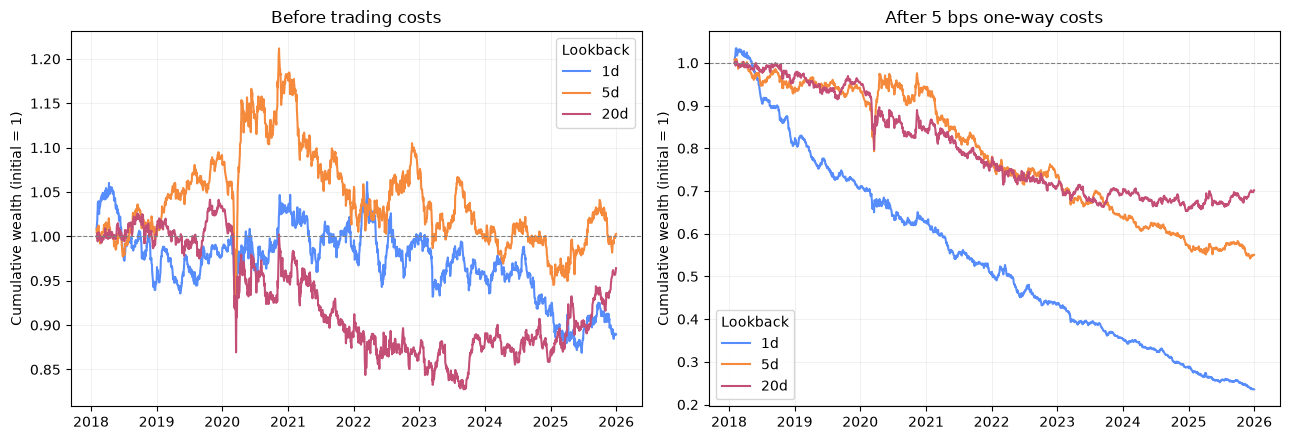

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for k in LOOKBACKS:
    result = backtests[k]
    gross_wealth = (1 + result["gross"]).cumprod()
    net_wealth = (1 + result["net"]).cumprod()
    axes[0].plot(gross_wealth.index, gross_wealth, label=f"{k}d")
    axes[1].plot(net_wealth.index, net_wealth, label=f"{k}d")

for ax, title in zip(axes, ["Before trading costs", "After 5 bps one-way costs"]):
    ax.set_title(title)
    ax.set_ylabel("Cumulative wealth (initial = 1)")
    ax.axhline(1, color="gray", linestyle="--", linewidth=0.8)
    ax.grid(alpha=0.25)
    ax.legend(title="Lookback")

plt.tight_layout()
plt.show()


## 7. Conclusion

1. **Limited Reversal Predictability:** Both 5-day and 20-day reversal factors exhibit near-zero gross Sharpe ratios (0.04 and −0.01), providing little evidence of profitable short-term reversal in the selected sector ETFs.

2. **Substantial Transaction Costs:** After transaction costs, Sharpe ratios decline to −0.90 and −0.52, respectively, indicating that trading costs can overwhelm weak reversal signals.

**Overall:** Short-term reversal strategies do not demonstrate economically meaningful profitability in this sample (2018–2025). These findings are specific to the selected ETFs and backtesting assumptions.